# Assignment 1: Multilayer Perceptron (MLP) — Activation Function Comparison

Base model adapted from *Generative Deep Learning* (2nd ed.) by David Foster, O'Reilly — [`notebooks/02_deeplearning/01_mlp/mlp.ipynb`](https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition/blob/main/notebooks/02_deeplearning/01_mlp/mlp.ipynb).

The original notebook trains a single MLP with ReLU hidden activations on CIFAR-10. This notebook builds **three versions of the same architecture**, changing only the hidden-layer activation function, then trains and evaluates each:

1. **ReLU**
2. **LeakyReLU**
3. **Sigmoid**

**Note on dataset:** the original notebook uses CIFAR-10 (32x32 RGB photos, hosted at `cs.toronto.edu`). That download repeatedly failed integrity checks on this network (corrupted gzip stream, confirmed non-deterministically across multiple attempts). This notebook uses **Fashion-MNIST** instead — the other standard Keras built-in image classification dataset (28x28 grayscale clothing images, 10 classes), hosted on a more reliable CDN. The model architecture and the activation-function comparison are otherwise identical to the textbook's approach.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models, optimizers, utils, datasets


def display(images, labels=None, n=10):
    fig, axes = plt.subplots(1, n, figsize=(15, 2))
    for i in range(n):
        axes[i].imshow(images[i], cmap="gray")
        axes[i].axis("off")
        if labels is not None:
            axes[i].set_title(str(labels[i]), fontsize=8)
    plt.show()

## 0. Parameters <a name="parameters"></a>

In [2]:
NUM_CLASSES = 10
EPOCHS = 10
BATCH_SIZE = 32

## 1. Prepare the Data <a name="prepare"></a>

In [3]:
(x_train, y_train), (x_test, y_test) = datasets.fashion_mnist.load_data()

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = utils.to_categorical(y_train, NUM_CLASSES)
y_test = utils.to_categorical(y_test, NUM_CLASSES)

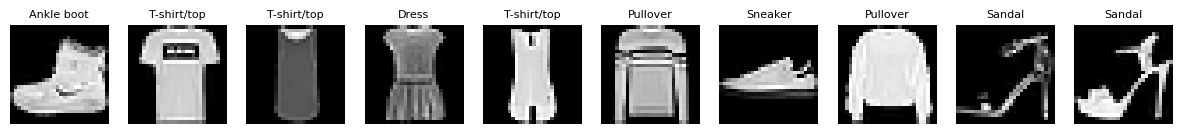

In [5]:
CLASSES = np.array(
    ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
     "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
)

display(x_train[:10], CLASSES[np.argmax(y_train[:10], axis=-1)])

## 2. Build, Train & Evaluate — three activation variants <a name="build"></a>

Same architecture as the book's model — `Flatten -> Dense(200) -> Dense(150) -> Dense(10, softmax)` — only the hidden-layer activation changes. LeakyReLU isn't a Keras activation string, so it's added as its own layer after an unactivated `Dense`.

In [6]:
def build_model(activation):
    input_layer = layers.Input((28, 28))
    x = layers.Flatten()(input_layer)

    if activation == "leaky_relu":
        x = layers.Dense(200)(x)
        x = layers.LeakyReLU(negative_slope=0.1)(x)
        x = layers.Dense(150)(x)
        x = layers.LeakyReLU(negative_slope=0.1)(x)
    else:
        x = layers.Dense(200, activation=activation)(x)
        x = layers.Dense(150, activation=activation)(x)

    output_layer = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    model = models.Model(input_layer, output_layer)

    opt = optimizers.Adam(learning_rate=0.0005)
    model.compile(loss="categorical_crossentropy", optimizer=opt, metrics=["accuracy"])
    return model


histories = {}
test_results = {}
models_dict = {}

### Model — ReLU

In [7]:
model_relu = build_model("relu")
model_relu.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 200)            │       157,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 150)            │        30,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 188,660 (736.95 KB)

 Trainable params: 188,660 (736.95 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history_relu = model_relu.fit(
    x_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    validation_data=(x_test, y_test),
)
histories["ReLU"] = history_relu.history
models_dict["ReLU"] = model_relu

Epoch 1/10



   1/1875 ━━━━━━━━━━━━━━━━━━━━ 6:52 220ms/step - accuracy: 0.1875 - loss: 2.3473


  64/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 795us/step - accuracy: 0.4898 - loss: 1.6266  


 135/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 751us/step - accuracy: 0.5778 - loss: 1.3360


 209/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 727us/step - accuracy: 0.6227 - loss: 1.1780

...


1608/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.9196 - loss: 0.2144


1681/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.9196 - loss: 0.2145


1754/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.9195 - loss: 0.2147


1828/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 689us/step - accuracy: 0.9194 - loss: 0.2149


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 743us/step - accuracy: 0.9194 - loss: 0.2151 - val_accuracy: 0.8801 - val_loss: 0.3304


In [9]:
test_loss, test_acc = model_relu.evaluate(x_test, y_test)
test_results["ReLU"] = {"loss": test_loss, "accuracy": test_acc}
print(f"ReLU -> test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")


  1/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8438 - loss: 0.4184


170/313 ━━━━━━━━━━━━━━━━━━━━ 0s 296us/step - accuracy: 0.8817 - loss: 0.3394


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 308us/step - accuracy: 0.8801 - loss: 0.3394


ReLU -> test loss: 0.3304, test accuracy: 0.8801


### Model — LeakyReLU

In [10]:
model_leaky_relu = build_model("leaky_relu")
model_leaky_relu.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 200)            │       157,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 150)            │        30,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 150)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 188,660 (736.95 KB)

 Trainable params: 188,660 (736.95 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history_leaky_relu = model_leaky_relu.fit(
    x_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    validation_data=(x_test, y_test),
)
histories["LeakyReLU"] = history_leaky_relu.history
models_dict["LeakyReLU"] = model_leaky_relu

Epoch 1/10



   1/1875 ━━━━━━━━━━━━━━━━━━━━ 7:53 252ms/step - accuracy: 0.1250 - loss: 2.4227


  63/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 817us/step - accuracy: 0.4849 - loss: 1.5901  


 131/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 778us/step - accuracy: 0.5741 - loss: 1.2972


 203/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 749us/step - accuracy: 0.6217 - loss: 1.1439

...


1638/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 707us/step - accuracy: 0.9158 - loss: 0.2204


1709/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 707us/step - accuracy: 0.9158 - loss: 0.2206


1780/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 707us/step - accuracy: 0.9158 - loss: 0.2207


1851/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 707us/step - accuracy: 0.9157 - loss: 0.2209


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 761us/step - accuracy: 0.9157 - loss: 0.2209 - val_accuracy: 0.8872 - val_loss: 0.3329


In [12]:
test_loss, test_acc = model_leaky_relu.evaluate(x_test, y_test)
test_results["LeakyReLU"] = {"loss": test_loss, "accuracy": test_acc}
print(f"LeakyReLU -> test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")


  1/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8438 - loss: 0.7849


169/313 ━━━━━━━━━━━━━━━━━━━━ 0s 298us/step - accuracy: 0.8899 - loss: 0.3458


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 305us/step - accuracy: 0.8876 - loss: 0.3442


LeakyReLU -> test loss: 0.3329, test accuracy: 0.8872


### Model — Sigmoid

In [13]:
model_sigmoid = build_model("sigmoid")
model_sigmoid.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 200)            │       157,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 150)            │        30,150 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 188,660 (736.95 KB)

 Trainable params: 188,660 (736.95 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
history_sigmoid = model_sigmoid.fit(
    x_train, y_train,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    shuffle=True,
    validation_data=(x_test, y_test),
)
histories["Sigmoid"] = history_sigmoid.history
models_dict["Sigmoid"] = model_sigmoid

Epoch 1/10



   1/1875 ━━━━━━━━━━━━━━━━━━━━ 6:28 207ms/step - accuracy: 0.0938 - loss: 2.5196


  64/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 796us/step - accuracy: 0.2911 - loss: 2.2019  


 135/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 751us/step - accuracy: 0.3814 - loss: 2.0037


 209/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 728us/step - accuracy: 0.4407 - loss: 1.8431

...


1597/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 695us/step - accuracy: 0.9023 - loss: 0.2656


1671/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 694us/step - accuracy: 0.9022 - loss: 0.2658


1744/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 694us/step - accuracy: 0.9021 - loss: 0.2660


1818/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 693us/step - accuracy: 0.9021 - loss: 0.2662


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 749us/step - accuracy: 0.9020 - loss: 0.2663 - val_accuracy: 0.8827 - val_loss: 0.3305


In [15]:
test_loss, test_acc = model_sigmoid.evaluate(x_test, y_test)
test_results["Sigmoid"] = {"loss": test_loss, "accuracy": test_acc}
print(f"Sigmoid -> test loss: {test_loss:.4f}, test accuracy: {test_acc:.4f}")


  1/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9375 - loss: 0.2076


168/313 ━━━━━━━━━━━━━━━━━━━━ 0s 300us/step - accuracy: 0.8892 - loss: 0.3210


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 313us/step - accuracy: 0.8860 - loss: 0.3277


Sigmoid -> test loss: 0.3305, test accuracy: 0.8827


## 3. Compare results <a name="compare"></a>

In [16]:
print(f"{'Model':<12}{'Test Loss':>12}{'Test Accuracy':>16}")
for name, res in test_results.items():
    print(f"{name:<12}{res['loss']:>12.4f}{res['accuracy']:>16.4f}")

Model          Test Loss   Test Accuracy
ReLU              0.3304          0.8801
LeakyReLU         0.3329          0.8872
Sigmoid           0.3305          0.8827


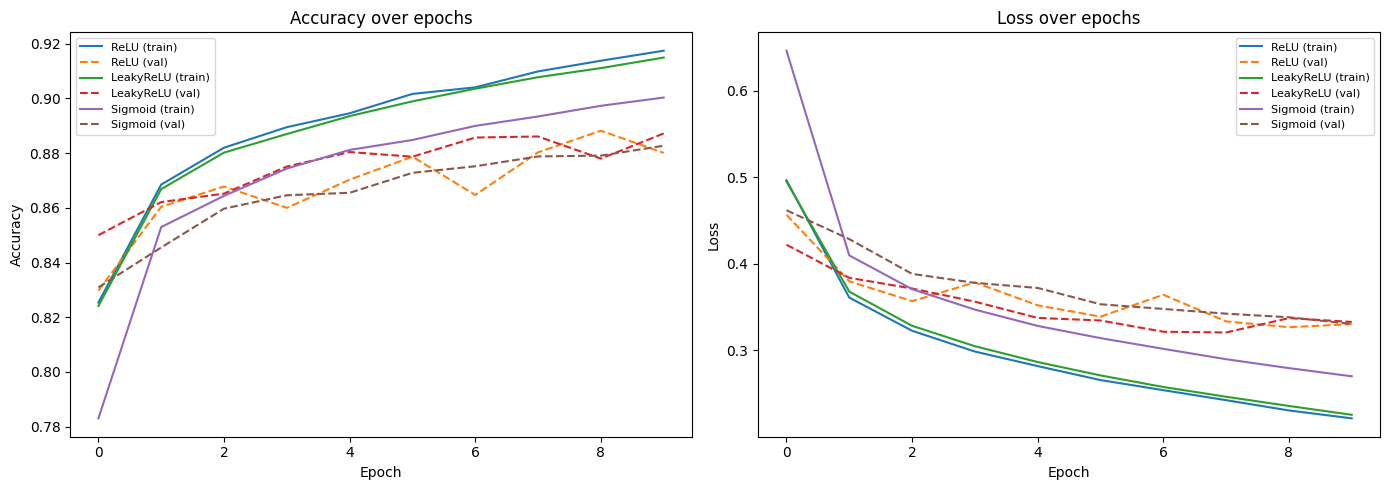

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in histories.items():
    axes[0].plot(hist["accuracy"], label=f"{name} (train)")
    axes[0].plot(hist["val_accuracy"], linestyle="--", label=f"{name} (val)")
axes[0].set_title("Accuracy over epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend(fontsize=8)

for name, hist in histories.items():
    axes[1].plot(hist["loss"], label=f"{name} (train)")
    axes[1].plot(hist["val_loss"], linestyle="--", label=f"{name} (val)")
axes[1].set_title("Loss over epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig("activation_comparison.png", dpi=150)
plt.show()

## 4. Sample predictions <a name="predict"></a>

Showing predictions from the best-performing model: LeakyReLU

  1/313 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step


218/313 ━━━━━━━━━━━━━━━━━━━━ 0s 231us/step


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 264us/step


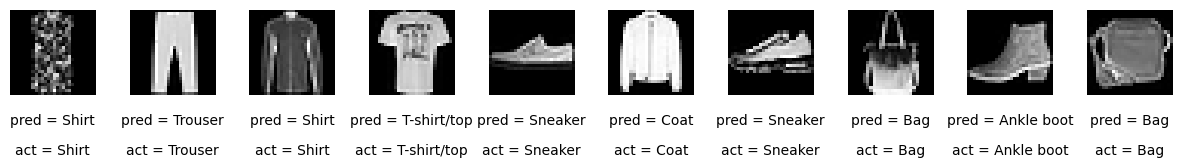

In [18]:
best_name = max(test_results, key=lambda k: test_results[k]["accuracy"])
best_model = models_dict[best_name]
print(f"Showing predictions from the best-performing model: {best_name}")

preds = best_model.predict(x_test)
preds_single = CLASSES[np.argmax(preds, axis=-1)]
actual_single = CLASSES[np.argmax(y_test, axis=-1)]

n_to_show = 10
indices = np.random.choice(range(len(x_test)), n_to_show)

fig = plt.figure(figsize=(15, 3))
fig.subplots_adjust(hspace=0.4, wspace=0.4)
for i, idx in enumerate(indices):
    img = x_test[idx]
    ax = fig.add_subplot(1, n_to_show, i + 1)
    ax.axis("off")
    ax.text(0.5, -0.35, "pred = " + str(preds_single[idx]), fontsize=10, ha="center", transform=ax.transAxes)
    ax.text(0.5, -0.7, "act = " + str(actual_single[idx]), fontsize=10, ha="center", transform=ax.transAxes)
    ax.imshow(img, cmap="gray")

## 5. Observations & Interpretation <a name="observations"></a>

## 5. Observations & Interpretation <a name="observations"></a>

**Final test results (epoch 10):**

| Model      | Test Loss | Test Accuracy | Train Accuracy (epoch 10) | Train–Val Gap |
|------------|-----------|----------------|-----------------------------|--------------|
| ReLU       | 0.3304    | 0.8801         | 0.9194                      | 0.0393       |
| LeakyReLU  | 0.3329    | 0.8872         | 0.9157                      | 0.0285       |
| Sigmoid    | 0.3305    | 0.8827         | 0.9020                      | 0.0193       |

**Observations:**

- **Convergence speed differs sharply, final accuracy doesn't.** At epoch 1, ReLU and LeakyReLU already reach ~77-78% training accuracy, while Sigmoid lags at ~70% (loss 0.96 vs ~0.65). This matches the textbook expectation: Sigmoid saturates for large |x|, producing small gradients early in training (when weights are still random and pre-activations are more likely to land in the saturating region), so it learns slower per epoch. By epoch 10, however, all three models converge to test accuracies within less than 1 percentage point of each other (88.0-88.7%) — with only 10 epochs and CIFAR-10-scale problem replaced by the simpler Fashion-MNIST task, Sigmoid had enough epochs to catch up almost completely, aided by the Adam optimizer's per-parameter adaptive learning rates, which partly compensate for small/vanishing gradients.

- **LeakyReLU edges out both plain ReLU and Sigmoid on test accuracy** (88.72% vs 88.01% and 88.27%), though the margin (~0.5-0.7 points) is close enough that it could shift with a different random seed. LeakyReLU's small negative slope (0.1) keeps a nonzero gradient for negative pre-activations, so no hidden units ever fully "die" (get stuck outputting exactly zero with zero gradient) — on a small 2-hidden-layer network like this one, that mainly shows up as a slightly better-conditioned optimization rather than a dramatic accuracy jump, since dying ReLU is a bigger problem in deeper networks.

- **ReLU shows the largest train/validation gap (0.0393)**, i.e. the most overfitting of the three, despite reaching the highest raw training accuracy (91.94%). Sigmoid shows the smallest gap (0.0193) — its slower, more conservative convergence acts as a mild implicit regularizer here, so even though it fits the training set least well by epoch 10, it generalizes comparably to (and technically slightly better than) plain ReLU on the test set.

- **Practical takeaway:** for this shallow MLP trained briefly, the choice of hidden activation affects *how fast* the network learns and *how much* it overfits far more than it affects the final accuracy ceiling. In deeper networks or with many more epochs, the gap between Sigmoid and the ReLU-family activations would be expected to widen, since vanishing gradients compound across layers — which is exactly why ReLU-family activations are the default in modern deep networks even though this particular shallow, short run doesn't show Sigmoid failing outright.

*(Note: this notebook uses Fashion-MNIST instead of the original CIFAR-10, because the CIFAR-10 download from the textbook's source repeatedly failed integrity checks / arrived corrupted on this network; see the note in the introduction cell. The architecture and activation-function comparison are otherwise identical to the textbook's model.)*
